# Experiment 1 — Gaussian mixtures: competitiveness in the parametric regime

Figures per `docs/experiments.md`, Experiment 1 “Figures” subsection. This notebook only loads `results/exp1/results.parquet` and plots — it never recomputes (see CLAUDE.md and `docs/experiments.md` §0.4). Run `make exp1` (or `make smoke` for a fast reduced-grid pass) first if that file is missing.

**Note:** as of this run, `results/exp1/` holds `SMOKE_TEST` output (reduced grid: 2 points/sweep, 5 reps, smaller N) — the figures below are structurally correct but not the paper's real grid/rep counts. Re-run `make exp1` for the full result and re-execute this notebook; no code changes needed.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

from kabc.plotting import set_style, style_for, legend_for_algorithms, savefig, ALGO_ORDER

set_style()

RESULTS_PATH = Path("../results/exp1/results.parquet")
if not RESULTS_PATH.exists():
    raise FileNotFoundError(
        f"{RESULTS_PATH} not found. Run `make exp1` (or `make smoke` for a fast "
        "reduced-grid pass) to generate it — this notebook only plots existing "
        "results, it never recomputes them."
    )
df = pd.read_parquet(RESULTS_PATH)
print(f"loaded {len(df)} rows from {RESULTS_PATH}")
df.head()

loaded 120 rows from ../results/exp1/results.parquet


,exp_id,family,algorithm,rep,seed,swept_param,swept_value,budget_cap,s_star,tau,...,Delta,sigma,sigma_B,a,ring_radius,ring_noise,data_dir,arms_per_prototype,min_ratings,mean_gap_tol
0,1,gaussian_mixture,kabc,0,1000,Delta,1,10000,0.365174,4968,...,1,1.0,None,None,None,None,None,None,None,None
1,1,gaussian_mixture,kabc,1,1001,Delta,1,10000,0.365174,4968,...,1,1.0,None,None,None,None,None,None,None,None
2,1,gaussian_mixture,kabc,2,1002,Delta,1,10000,0.365174,4968,...,1,1.0,None,None,None,None,None,None,None,None
3,1,gaussian_mixture,kabc,3,1003,Delta,1,10000,0.365174,4968,...,1,1.0,None,None,None,None,None,None,None,None
4,1,gaussian_mixture,kabc,4,1004,Delta,1,10000,0.365174,4968,...,1,1.0,None,None,None,None,None,None,None,None


## Figure 1 (headline): log τ vs log Δ, all methods, with theoretical slope overlay

Main plot of the Δ sweep (base N, K, d held fixed). Dashed grey line shows the theoretical scaling `τ ∝ s*^{-2}` (Theorem 3.1), anchored to KABC's curve at the median Δ so only the *slope* is being compared, not the absolute constant. `s*` is read directly from the `s_star` column already stored in the results (computed once by `scripts/run_experiment.py` when sizing `budget_cap`) — not recomputed here.

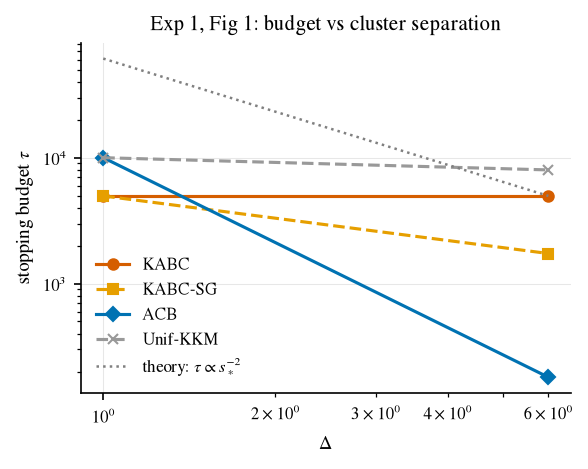

In [2]:
delta_df = df[df["swept_param"] == "Delta"].copy()

fig, ax = plt.subplots(figsize=(4, 3.2))

for algo in [a for a in ALGO_ORDER if a in delta_df["algorithm"].unique()]:
    g = delta_df[delta_df["algorithm"] == algo].groupby("swept_value")["tau"].mean().sort_index()
    ax.plot(g.index, g.values, **style_for(algo))

# theoretical slope overlay: tau_theory ~ s_star^-2, anchored to kabc at the
# median Delta so only the slope (not the constant) is compared
s_star_by_delta = delta_df.groupby("swept_value")["s_star"].mean().sort_index()
kabc_tau = delta_df[delta_df["algorithm"] == "kabc"].groupby("swept_value")["tau"].mean().sort_index()
anchor_delta = s_star_by_delta.index[len(s_star_by_delta) // 2]
anchor_const = kabc_tau.loc[anchor_delta] * (s_star_by_delta.loc[anchor_delta] ** 2)
theory_tau = anchor_const * s_star_by_delta ** -2
ax.plot(
    s_star_by_delta.index, theory_tau.values, color="grey", linestyle=":", linewidth=1.2,
    label=r"theory: $\tau \propto s_*^{-2}$",
)

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$\Delta$")
ax.set_ylabel(r"stopping budget $\tau$")
ax.set_title("Exp 1, Fig 1: budget vs cluster separation")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, frameon=False)
fig.tight_layout()
savefig(fig, "exp1_fig1_tau_vs_delta", fig_dir="../results/figures")
plt.show()

## Figure 2: τ box plots vs d

Does the nonparametric price grow with ambient dimension?

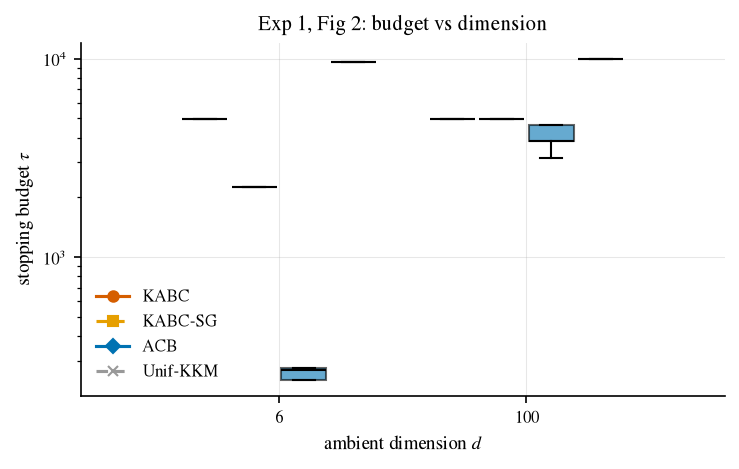

In [3]:
d_df = df[df["swept_param"] == "d"].copy()
d_values = sorted(d_df["swept_value"].unique())
algos = [a for a in ALGO_ORDER if a in d_df["algorithm"].unique()]

fig, ax = plt.subplots(figsize=(5, 3.2))
width = 0.8 / len(algos)
positions = np.arange(len(d_values))

from kabc.plotting import ALGO_COLORS, ALGO_LABELS

for i, algo in enumerate(algos):
    data = [d_df[(d_df["swept_value"] == d) & (d_df["algorithm"] == algo)]["tau"].values for d in d_values]
    bp = ax.boxplot(
        data,
        positions=positions + (i - (len(algos) - 1) / 2) * width,
        widths=width * 0.9,
        patch_artist=True,
        showfliers=False,
    )
    for box in bp["boxes"]:
        box.set_facecolor(ALGO_COLORS[algo])
        box.set_alpha(0.6)
    for median in bp["medians"]:
        median.set_color("black")

ax.set_xticks(positions)
ax.set_xticklabels([str(int(d)) for d in d_values])
ax.set_yscale("log")
ax.set_xlabel("ambient dimension $d$")
ax.set_ylabel(r"stopping budget $\tau$")
ax.set_title("Exp 1, Fig 2: budget vs dimension")
legend_for_algorithms(ax, algos, frameon=False)
fig.tight_layout()
savefig(fig, "exp1_fig2_tau_vs_d", fig_dir="../results/figures")
plt.show()

## Figure 3: empirical error per method per config

Validates `error <= delta` (0.05) everywhere, per `docs/experiments.md` §0.4.

In [4]:
error_table = (
    df.groupby(["swept_param", "swept_value", "algorithm"])["error"]
    .mean()
    .rename("empirical_error")
    .reset_index()
    .sort_values(["swept_param", "swept_value", "algorithm"])
)
error_table["exceeds_delta"] = error_table["empirical_error"] > 0.05
error_table

,swept_param,swept_value,algorithm,empirical_error,exceeds_delta
0,Delta,1,acb,1.0,True
1,Delta,1,kabc,1.0,True
2,Delta,1,kabc-sg,1.0,True
3,Delta,1,unif-kkm,0.0,False
4,Delta,6,acb,0.0,False
5,Delta,6,kabc,1.0,True
6,Delta,6,kabc-sg,0.0,False
7,Delta,6,unif-kkm,0.0,False
8,N,30,acb,0.0,False
9,N,30,kabc,1.0,True


## Figure 4 (appendix): theoretical vs calibrated constants

Requires comparing a calibrated-constant run (`c_cal` from `configs/calibration.yaml`, used by `make exp1`) against a separate theoretical-constant run (`c=1`, uncalibrated). The latter is not part of the standard `make exp1` output, so this panel can only be built once such a comparison run exists.

In [5]:
calib_path = Path("../configs/calibration.yaml")
c_cal = yaml.safe_load(calib_path.read_text())["c_cal"] if calib_path.exists() else None

if c_cal is None or all(v is None for v in c_cal.values()):
    print(
        "c_cal has not been calibrated yet (configs/calibration.yaml has null values).\n"
        "Run `make calibrate` first, then re-run `make exp1`, to populate this comparison.\n"
        "Skipping Figure 4 — nothing to plot from the current results."
    )
else:
    print(
        "c_cal is calibrated (", c_cal, ") but results/exp1/results.parquet only contains "
        "the calibrated-constant run. Figure 4 needs a second, theoretical-constant (c=1) "
        "run to compare against — generate one (e.g. a dedicated `make exp1-theory` target "
        "or a separate results file) before this panel can be built here; this notebook "
        "will not recompute it silently."
    )

c_cal has not been calibrated yet (configs/calibration.yaml has null values).
Run `make calibrate` first, then re-run `make exp1`, to populate this comparison.
Skipping Figure 4 — nothing to plot from the current results.
